In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("FuelConsumption.csv")
df

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2014,VOLVO,XC60 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1063,2014,VOLVO,XC60 AWD,SUV - SMALL,3.2,6,AS6,X,13.2,9.5,11.5,25,264
1064,2014,VOLVO,XC70 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1065,2014,VOLVO,XC70 AWD,SUV - SMALL,3.2,6,AS6,X,12.9,9.3,11.3,25,260


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 108.5+ KB


In [3]:
df.isnull().sum()

MODELYEAR                   0
MAKE                        0
MODEL                       0
VEHICLECLASS                0
ENGINESIZE                  0
CYLINDERS                   0
TRANSMISSION                0
FUELTYPE                    0
FUELCONSUMPTION_CITY        0
FUELCONSUMPTION_HWY         0
FUELCONSUMPTION_COMB        0
FUELCONSUMPTION_COMB_MPG    0
CO2EMISSIONS                0
dtype: int64

In [4]:
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [5]:
df.tail()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
1062,2014,VOLVO,XC60 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1063,2014,VOLVO,XC60 AWD,SUV - SMALL,3.2,6,AS6,X,13.2,9.5,11.5,25,264
1064,2014,VOLVO,XC70 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1065,2014,VOLVO,XC70 AWD,SUV - SMALL,3.2,6,AS6,X,12.9,9.3,11.3,25,260
1066,2014,VOLVO,XC90 AWD,SUV - STANDARD,3.2,6,AS6,X,14.9,10.2,12.8,22,294


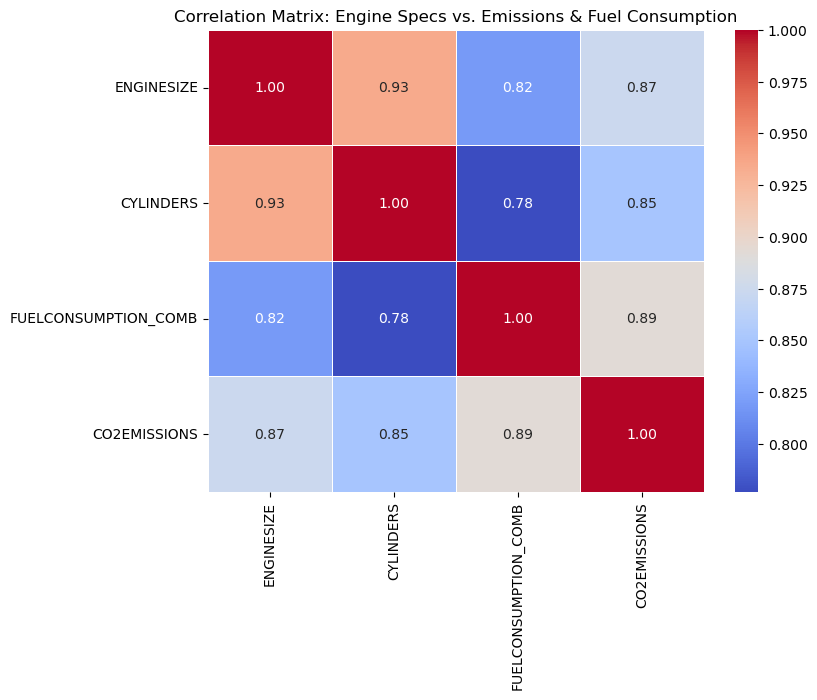

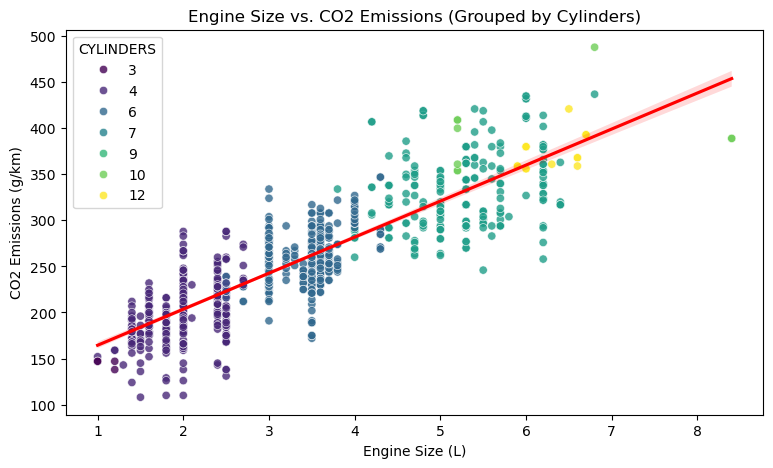

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Select the relevant features and compute correlation
features = ['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS']
corr = df[features].corr()

# 2. Plot a Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix: Engine Specs vs. Emissions & Fuel Consumption')
plt.show()

# 3. Scatter Plot: Engine Size vs. CO2 Emissions with Cylinder Hue
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='ENGINESIZE', y='CO2EMISSIONS', hue='CYLINDERS', palette='viridis', alpha=0.8)
sns.regplot(data=df, x='ENGINESIZE', y='CO2EMISSIONS', scatter=False, color='red')
plt.title('Engine Size vs. CO2 Emissions (Grouped by Cylinders)')
plt.xlabel('Engine Size (L)')
plt.ylabel('CO2 Emissions (g/km)')
plt.show()

### Key Analytical Takeaways: Engine Specs vs. Emissions & Fuel Consumption

* **Strong Direct Relationship ($r = 0.87$):** Engine size (`ENGINESIZE`) exhibits a very strong positive linear correlation with $\text{CO}_2$ emissions. Larger engine displacements directly translate to higher carbon emissions.
* **Cylinder Count Impact ($r = 0.85$):** The number of cylinders (`CYLINDERS`) shows an almost equally strong positive correlation with emissions, with higher cylinder counts (V6, V8, V12) consistently clustered at higher emission tiers.
* **Fuel Consumption Link ($r = 0.89$):** Combined fuel consumption (`FUELCONSUMPTION_COMB`) has the highest correlation with $\text{CO}_2$ emissions, confirming that fuel volume burned is the most direct operational driver of emissions.
* **Multicollinearity Caution ($r = 0.93$):** `ENGINESIZE` and `CYLINDERS` are heavily collinear with each other. If building predictive models (such as Multiple Linear Regression), using both simultaneously can cause multicollinearity issues; selecting one or using dimensionality reduction is recommended.

### **Average fuel Efficiency**

In [8]:
# Group by vehicle class and calculate average fuel efficiency
fuel_efficiency = df.groupby("VEHICLECLASS").agg(
    Average_MPG=("FUELCONSUMPTION_COMB_MPG", "mean"),
    Average_L_100km=("FUELCONSUMPTION_COMB", "mean")
).reset_index()

# Round values to 2 decimal places
fuel_efficiency[["Average_MPG", "Average_L_100km"]] = (
    fuel_efficiency[["Average_MPG", "Average_L_100km"]].round(2)
)

# Display all vehicle classes
display(fuel_efficiency.sort_values("Average_MPG", ascending=False))

# Find the most and least fuel-efficient classes
most_efficient = fuel_efficiency.loc[
    fuel_efficiency["Average_MPG"].idxmax()
]

least_efficient = fuel_efficiency.loc[
    fuel_efficiency["Average_MPG"].idxmin()
]

print("Most fuel-efficient vehicle class:")
print(most_efficient)

print("\nLeast fuel-efficient vehicle class:")
print(least_efficient)


,VEHICLECLASS,Average_MPG,Average_L_100km
0,COMPACT,31.15,9.51
9,STATION WAGON - SMALL,30.86,9.51
2,MID-SIZE,30.33,9.94
8,STATION WAGON - MID-SIZE,30.17,10.25
3,MINICOMPACT,28.96,10.24
7,SPECIAL PURPOSE VEHICLE,27.86,10.23
10,SUBCOMPACT,27.09,10.98
11,SUV - SMALL,27.03,10.70
13,TWO-SEATER,26.56,11.55
1,FULL-SIZE,24.02,12.16


Most fuel-efficient vehicle class:
VEHICLECLASS       COMPACT
Average_MPG          31.15
Average_L_100km       9.51
Name: 0, dtype: object

Least fuel-efficient vehicle class:
VEHICLECLASS       VAN - PASSENGER
Average_MPG                   14.2
Average_L_100km              20.33
Name: 15, dtype: object


### **Graph for comparing average MPG**

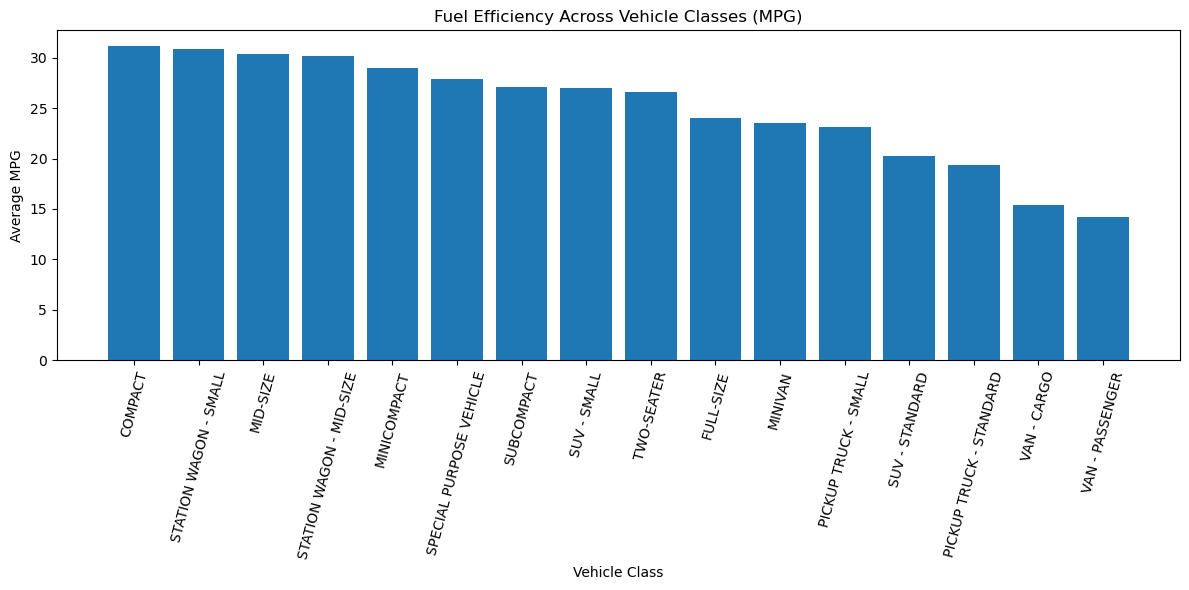

In [9]:

mpg_data = fuel_efficiency.sort_values(
    "Average_MPG", ascending=False
)

plt.figure(figsize=(12, 6))
plt.bar(mpg_data["VEHICLECLASS"], mpg_data["Average_MPG"])

plt.title("Fuel Efficiency Across Vehicle Classes (MPG)")
plt.xlabel("Vehicle Class")
plt.ylabel("Average MPG")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


### **Graph for comparing L/100 km**

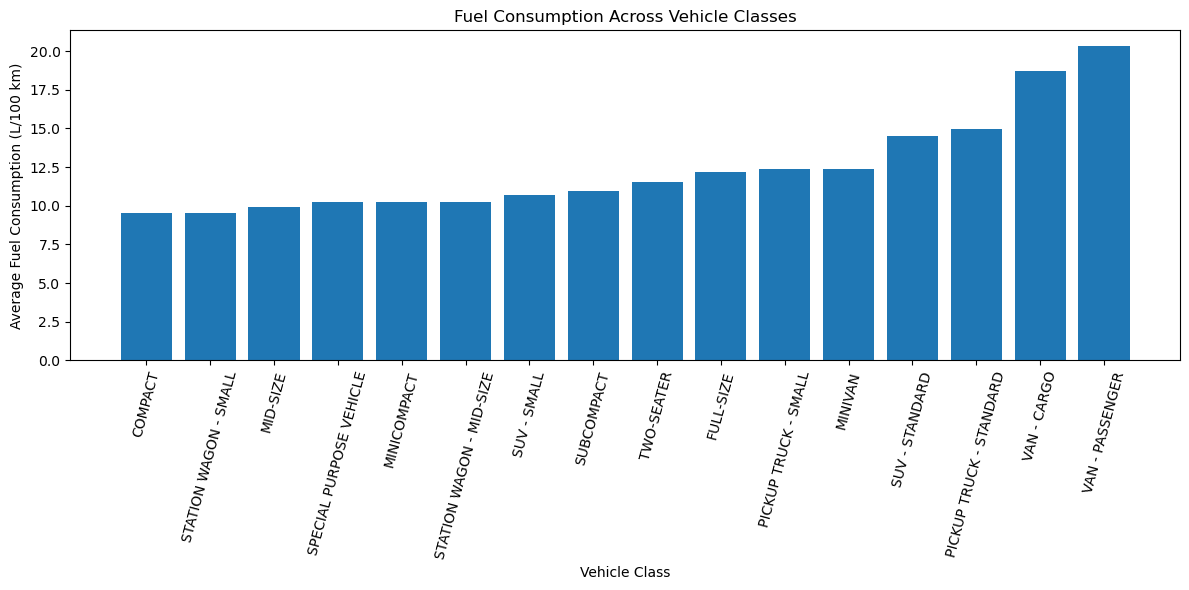

In [10]:

consumption_data = fuel_efficiency.sort_values(
    "Average_L_100km", ascending=True
)

plt.figure(figsize=(12, 6))
plt.bar(
    consumption_data["VEHICLECLASS"],
    consumption_data["Average_L_100km"]
)

plt.title("Fuel Consumption Across Vehicle Classes")
plt.xlabel("Vehicle Class")
plt.ylabel("Average Fuel Consumption (L/100 km)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


## Final Result: Fuel Efficiency Across Vehicle Classes

The analysis of the `FuelConsumption.csv` dataset shows that **COMPACT vehicles are the most fuel-efficient**, while **VAN - PASSENGER vehicles are the least fuel-efficient** based on average combined fuel economy.

| Vehicle Class | Average MPG | Average Fuel Consumption (L/100 km) |
|---|---:|---:|
| COMPACT | 31.15 | 9.51 |
| VAN - PASSENGER | 14.20 | 20.33 |

### Key Findings

- **Most fuel-efficient:** COMPACT vehicles, with an average of 31.15 MPG and 9.51 L/100 km.
- **Least fuel-efficient:** VAN - PASSENGER vehicles, with an average of 14.20 MPG and 20.33 L/100 km.
- **MPG interpretation:** Higher MPG indicates better fuel efficiency.
- **L/100 km interpretation:** Lower fuel consumption indicates better fuel efficiency.

### Conclusion

Compact vehicles offer better fuel economy than passenger vans in this dataset. Passenger vans consume more fuel per 100 km, whereas compact vehicles travel farther per unit of fuel. These findings highlight the relationship between vehicle class and fuel efficiency.

### **Calculate average emissions and fuel consumption by fuel type**

In [11]:

fuel_impact = df.groupby('FUELTYPE').agg(
    Vehicle_Count=('FUELTYPE', 'count'),
    Average_CO2_Emissions=('CO2EMISSIONS', 'mean'),
    Average_Fuel_Consumption=('FUELCONSUMPTION_COMB', 'mean'),
    Average_MPG=('FUELCONSUMPTION_COMB_MPG', 'mean')
).reset_index()

fuel_impact = fuel_impact.round(2)

display(fuel_impact)


,FUELTYPE,Vehicle_Count,Average_CO2_Emissions,Average_Fuel_Consumption,Average_MPG
0,D,27,227.78,8.44,34.63
1,E,92,291.09,18.19,16.11
2,X,514,241.10,10.48,28.77
3,Z,434,268.53,11.68,25.36


Explanation:
- groupby('FUELTYPE') groups vehicles by fuel type.
- mean calculates the average emissions and fuel economy.
- count counts the number of vehicles in each fuel category.
- round(2) displays results to two decimal places.

### **Find the highest and lowest emissions**

In [12]:

highest_emissions = fuel_impact.loc[
    fuel_impact['Average_CO2_Emissions'].idxmax()
]

lowest_emissions = fuel_impact.loc[
    fuel_impact['Average_CO2_Emissions'].idxmin()
]

print("Fuel type with highest average CO2 emissions:")
print(highest_emissions[['FUELTYPE', 'Average_CO2_Emissions']])

print("\nFuel type with lowest average CO2 emissions:")
print(lowest_emissions[['FUELTYPE', 'Average_CO2_Emissions']])


Fuel type with highest average CO2 emissions:
FUELTYPE                      E
Average_CO2_Emissions    291.09
Name: 1, dtype: object

Fuel type with lowest average CO2 emissions:
FUELTYPE                      D
Average_CO2_Emissions    227.78
Name: 0, dtype: object


### **Compare CO₂ emissions by fuel type**

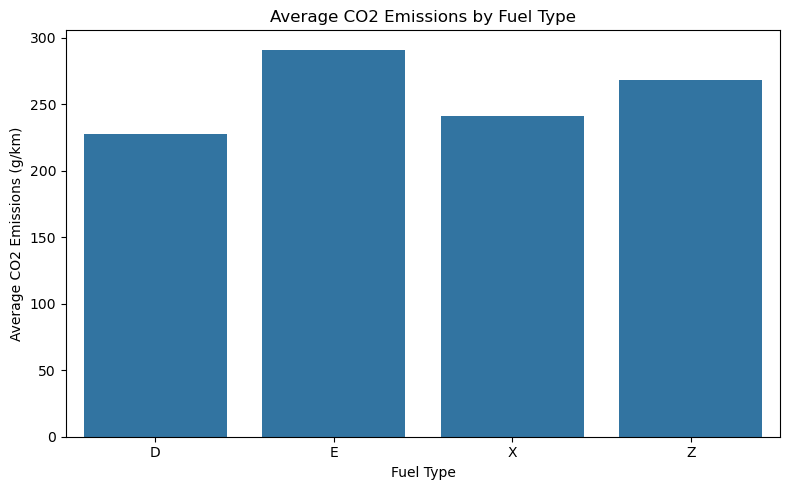

In [13]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=fuel_impact,
    x='FUELTYPE',
    y='Average_CO2_Emissions'
)

plt.title('Average CO2 Emissions by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average CO2 Emissions (g/km)')
plt.tight_layout()
plt.show()


### **Compare fuel consumption by fuel type**

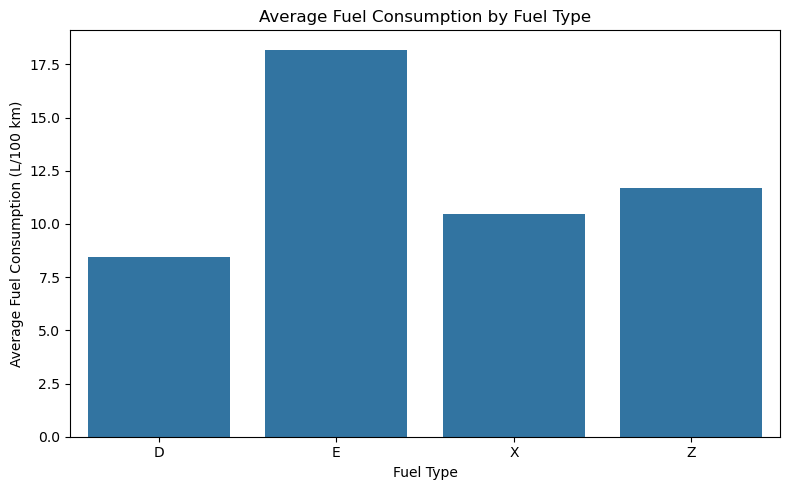

In [14]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=fuel_impact,
    x='FUELTYPE',
    y='Average_Fuel_Consumption'
)

plt.title('Average Fuel Consumption by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Fuel Consumption (L/100 km)')
plt.tight_layout()
plt.show()


### **Compare fuel efficiency (MPG)**

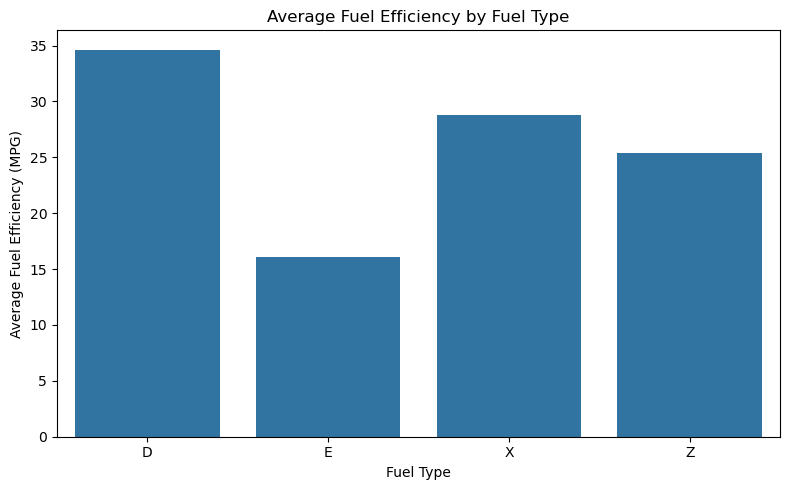

In [15]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=fuel_impact,
    x='FUELTYPE',
    y='Average_MPG'
)

plt.title('Average Fuel Efficiency by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Fuel Efficiency (MPG)')
plt.tight_layout()
plt.show()


### **Display the final ranking**

In [16]:

print("Fuel types ranked by lowest CO2 emissions:")
display(
    fuel_impact.sort_values(
        by='Average_CO2_Emissions',
        ascending=True
    )
)

print("Fuel types ranked by lowest fuel consumption:")
display(
    fuel_impact.sort_values(
        by='Average_Fuel_Consumption',
        ascending=True
    )
)

print("Fuel types ranked by highest fuel efficiency:")
display(
    fuel_impact.sort_values(
        by='Average_MPG',
        ascending=False
    )
)


Fuel types ranked by lowest CO2 emissions:


,FUELTYPE,Vehicle_Count,Average_CO2_Emissions,Average_Fuel_Consumption,Average_MPG
0,D,27,227.78,8.44,34.63
2,X,514,241.10,10.48,28.77
3,Z,434,268.53,11.68,25.36
1,E,92,291.09,18.19,16.11


Fuel types ranked by lowest fuel consumption:


,FUELTYPE,Vehicle_Count,Average_CO2_Emissions,Average_Fuel_Consumption,Average_MPG
0,D,27,227.78,8.44,34.63
2,X,514,241.10,10.48,28.77
3,Z,434,268.53,11.68,25.36
1,E,92,291.09,18.19,16.11


Fuel types ranked by highest fuel efficiency:


,FUELTYPE,Vehicle_Count,Average_CO2_Emissions,Average_Fuel_Consumption,Average_MPG
0,D,27,227.78,8.44,34.63
2,X,514,241.10,10.48,28.77
3,Z,434,268.53,11.68,25.36
1,E,92,291.09,18.19,16.11


## Final Result: Impact of Fuel Type on Carbon Emissions and Fuel Consumption

The analysis of the `FuelConsumption.csv` dataset compares fuel types (`FUELTYPE`) based on average CO₂ emissions, combined fuel consumption, and fuel efficiency.

### Results by Fuel Type

| Fuel Type | Vehicle Count | Average CO₂ Emissions (g/km) | Average Fuel Consumption (L/100 km) | Average MPG |
|---|---:|---:|---:|---:|
| D | 27 | 227.78 | 8.44 | 34.63 |
| E | 92 | 291.09 | 18.19 | 16.11 |
| X | 514 | 241.10 | 10.48 | 28.77 |
| Z | 434 | 268.53 | 11.68 | 25.36 |

### Key Findings

- **Lowest CO₂ emissions:** Fuel type D, averaging 227.78 g/km.
- **Highest CO₂ emissions:** Fuel type E, averaging 291.09 g/km.
- **Lowest fuel consumption:** Fuel type D, averaging 8.44 L/100 km.
- **Highest fuel consumption:** Fuel type E, averaging 18.19 L/100 km.
- **Highest fuel efficiency:** Fuel type D, averaging 34.63 MPG.
- **Lowest fuel efficiency:** Fuel type E, averaging 16.11 MPG.

### Conclusion

Fuel type D demonstrates the best average fuel economy and the lowest average CO₂ emissions in this dataset. In contrast, fuel type E has the highest average emissions and fuel consumption and the lowest average MPG.

These results show an association between fuel type and vehicle fuel performance. However, vehicle class, engine size, and other characteristics may also contribute to these differences.

### **Calculate average emissions, engine size, and fuel efficiency by make**

In [17]:

make_analysis = df.groupby("MAKE").agg(
    Vehicle_Count=("MAKE", "count"),
    Average_CO2_Emissions=("CO2EMISSIONS", "mean"),
    Average_Engine_Size=("ENGINESIZE", "mean"),
    Average_Fuel_Consumption=("FUELCONSUMPTION_COMB", "mean"),
    Average_MPG=("FUELCONSUMPTION_COMB_MPG", "mean")
).reset_index()

make_analysis = make_analysis.round(2)

display(make_analysis)


,MAKE,Vehicle_Count,Average_CO2_Emissions,Average_Engine_Size,Average_Fuel_Consumption,Average_MPG
0,ACURA,12,226.00,2.97,9.83,29.50
1,ASTON MARTIN,7,351.57,5.21,15.29,18.29
2,AUDI,49,275.69,3.23,11.79,24.94
3,BENTLEY,8,359.00,5.35,15.60,18.25
4,BMW,64,252.11,3.19,10.91,26.88
5,BUICK,16,235.69,2.60,10.86,27.12
6,CADILLAC,32,287.34,4.09,12.90,22.88
7,CHEVROLET,86,272.93,3.80,13.17,24.40
8,CHRYSLER,19,251.37,3.72,12.12,23.89
9,DODGE,39,249.59,3.63,11.78,25.08


### **Find the most eco-friendly car makes**

In [18]:

eligible_makes = make_analysis[
    make_analysis["Vehicle_Count"] >= 5
]

eco_friendly = eligible_makes.sort_values(
    by="Average_CO2_Emissions",
    ascending=True
)

display(eco_friendly.head(10))


,MAKE,Vehicle_Count,Average_CO2_Emissions,Average_Engine_Size,Average_Fuel_Consumption,Average_MPG
10,FIAT,10,179.50,1.40,7.81,36.30
26,MINI,36,188.53,1.60,8.20,34.33
24,MAZDA,27,193.04,2.29,8.39,34.59
32,SCION,9,198.89,2.08,8.64,33.44
13,HONDA,21,203.71,2.54,8.86,33.76
27,MITSUBISHI,16,210.50,2.04,9.15,32.00
37,VOLKSWAGEN,42,216.00,2.21,9.12,31.86
14,HYUNDAI,24,217.25,2.32,9.44,30.92
18,KIA,33,217.52,2.12,9.46,30.39
35,SUBARU,23,225.13,2.43,9.78,29.61


### **Find car makes with high emissions and larger engines**

In [19]:

high_emission_makes = eligible_makes.sort_values(
    by=["Average_CO2_Emissions", "Average_Engine_Size"],
    ascending=[False, False]
)

display(high_emission_makes.head(10))


,MAKE,Vehicle_Count,Average_CO2_Emissions,Average_Engine_Size,Average_Fuel_Consumption,Average_MPG
31,ROLLS-ROYCE,7,381.00,6.66,16.57,17.43
3,BENTLEY,8,359.00,5.35,15.60,18.25
1,ASTON MARTIN,7,351.57,5.21,15.29,18.29
12,GMC,49,328.24,5.02,16.76,17.67
23,MASERATI,6,319.67,3.70,13.90,20.33
20,LAND ROVER,19,307.84,3.79,14.96,19.84
30,RAM,13,291.23,4.15,13.57,21.54
16,JAGUAR,22,290.68,4.41,13.37,21.55
6,CADILLAC,32,287.34,4.09,12.90,22.88
25,MERCEDES-BENZ,59,277.68,4.21,12.12,24.41


### **Visualize average CO₂ emissions by make**

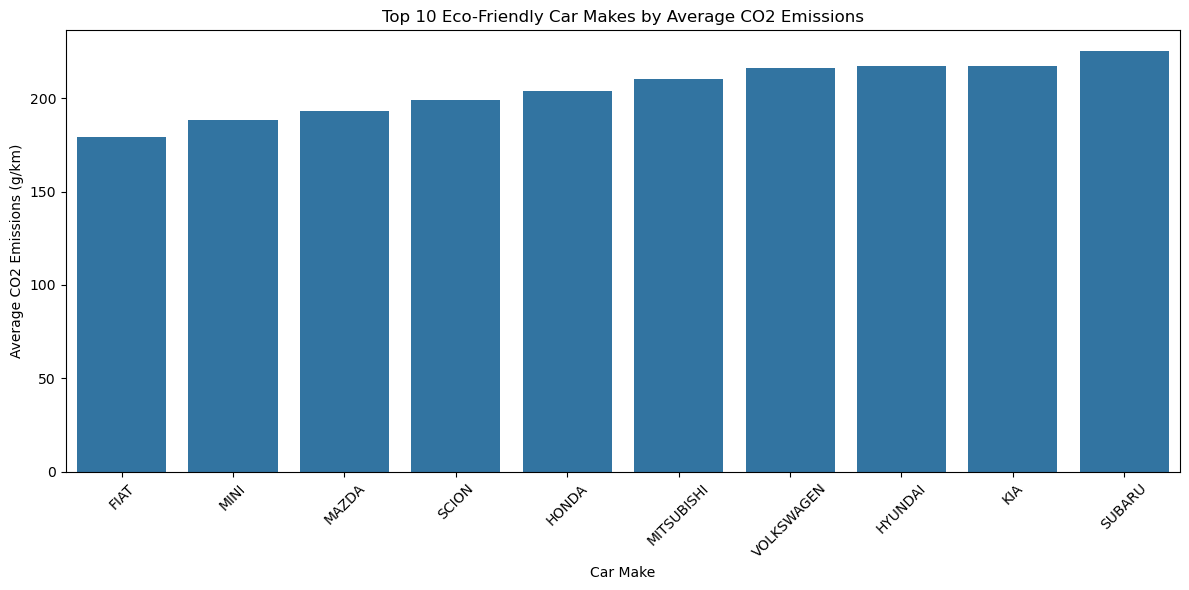

In [20]:

top_eco = eco_friendly.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_eco,
    x="MAKE",
    y="Average_CO2_Emissions"
)

plt.title("Top 10 Eco-Friendly Car Makes by Average CO2 Emissions")
plt.xlabel("Car Make")
plt.ylabel("Average CO2 Emissions (g/km)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### **Visualize engine size versus CO₂ emissions**

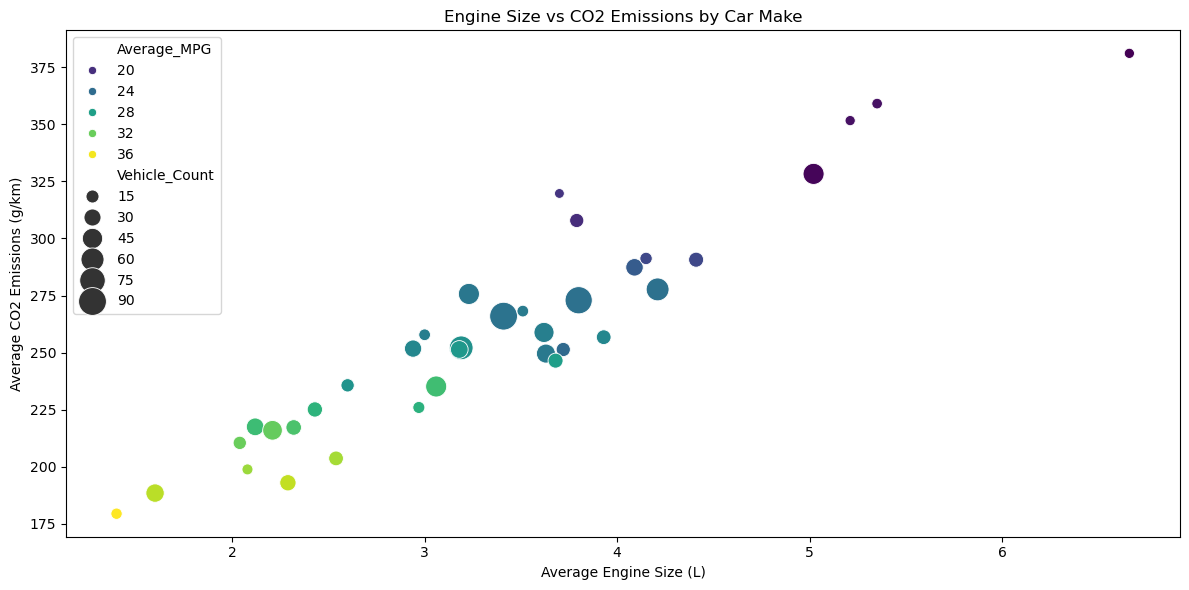

In [21]:

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=eligible_makes,
    x="Average_Engine_Size",
    y="Average_CO2_Emissions",
    size="Vehicle_Count",
    hue="Average_MPG",
    sizes=(50, 400),
    palette="viridis"
)

plt.title("Engine Size vs CO2 Emissions by Car Make")
plt.xlabel("Average Engine Size (L)")
plt.ylabel("Average CO2 Emissions (g/km)")
plt.tight_layout()
plt.show()


### **Compare fuel efficiency across manufacturers**

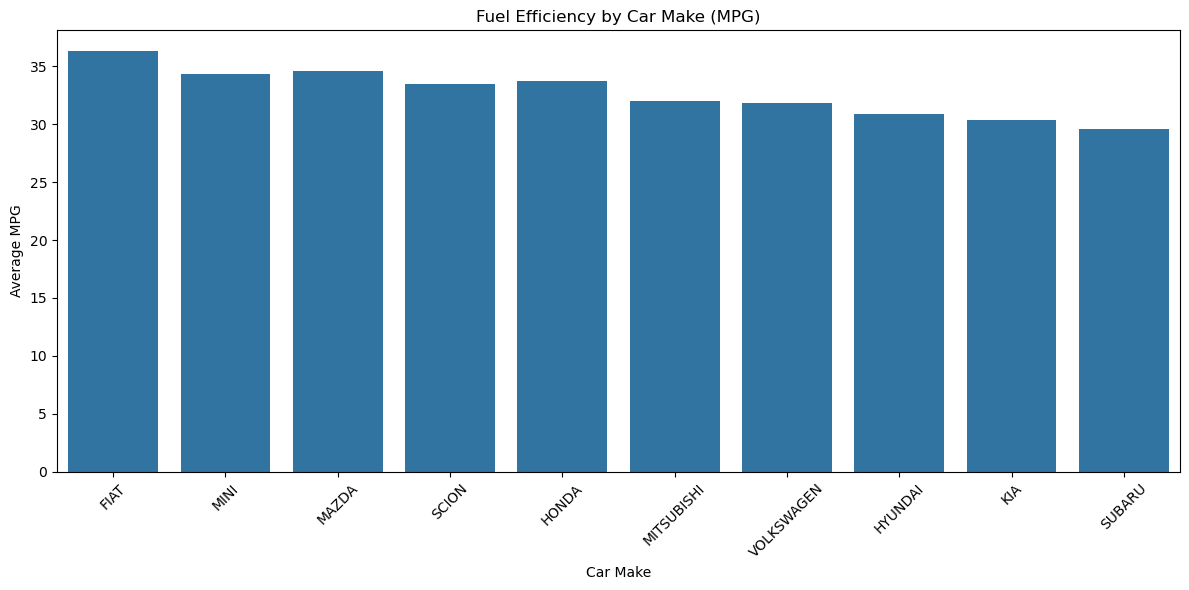

In [22]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=eco_friendly.head(10),
    x="MAKE",
    y="Average_MPG"
)

plt.title("Fuel Efficiency by Car Make (MPG)")
plt.xlabel("Car Make")
plt.ylabel("Average MPG")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Final Result: Manufacturer/Make Analysis

The analysis of the `FuelConsumption.csv` dataset identifies which car makes are the most eco-friendly and which tend to have higher carbon emissions and larger engines. To ensure a fairer comparison, only manufacturers with at least five vehicles in the dataset are included.

### 1. Most Eco-Friendly Car Makes

| Car Make | Average CO₂ Emissions (g/km) | Average Engine Size (L) | Average Fuel Consumption (L/100 km) | Average MPG |
|---|---:|---:|---:|---:|
| FIAT | 179.50 | 1.40 | 7.81 | 36.30 |
| MINI | 188.53 | 1.60 | 8.20 | 34.33 |
| MAZDA | 193.04 | 2.29 | 8.39 | 34.59 |
| SCION | 198.89 | 2.08 | 8.64 | 33.44 |
| HONDA | 203.71 | 2.54 | 8.86 | 33.76 |

**Key finding:** FIAT is the most eco-friendly make in this dataset by average CO₂ emissions, with 179.50 g/km. It also has the lowest average engine size and fuel consumption among these manufacturers.

### 2. Car Makes with High Emissions and Larger Engines

| Car Make | Average CO₂ Emissions (g/km) | Average Engine Size (L) | Average Fuel Consumption (L/100 km) | Average MPG |
|---|---:|---:|---:|---:|
| ROLLS-ROYCE | 381.00 | 6.66 | 16.57 | 17.43 |
| BENTLEY | 359.00 | 5.35 | 15.60 | 18.25 |
| ASTON MARTIN | 351.57 | 5.21 | 15.29